In [109]:
import pickle
import pandas as pd
import numpy as np
import tqdm
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

In [110]:
def visualize_metrics(df, model_name, metric_name, save = False):
    df_sorted = df.sort_index()
    means = df_sorted.mean(axis=1)
    stds = df_sorted.std(axis=1)
    
    layers = df_sorted.index
    
    plt.figure()
    plt.bar(
        layers,
        means,
        yerr=stds,
        capsize=8,                 
        error_kw={
            "elinewidth": 0.5,      
            "capthick": 1,         
            "alpha": 0.6
        }
    )
    
    plt.title(f"{metric_name} for different layers of {model_name}")
    plt.xlabel("Layer number")
    plt.ylabel("Value")

    plt.xticks(layers, rotation=90)
    plt.tight_layout()
    if save:
        plt.savefig(f'../data/metrics/compare_metrics/{model_name}_{metric_name}.png')
    plt.show()

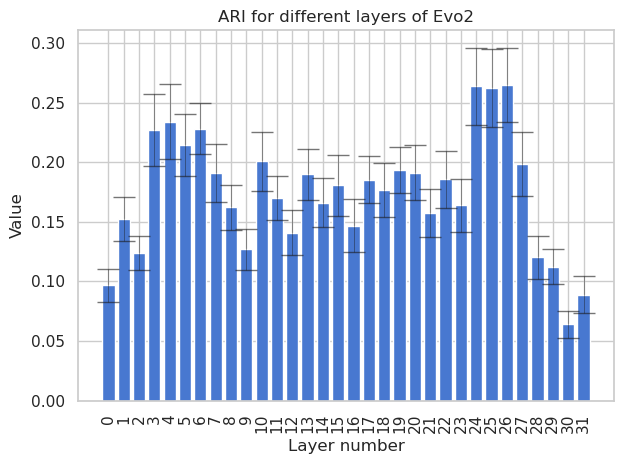

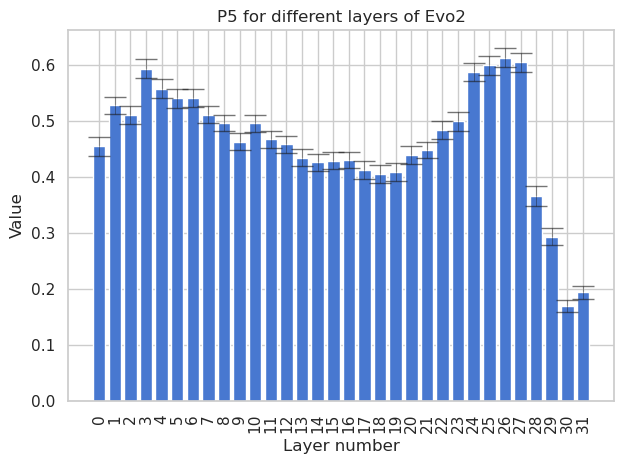

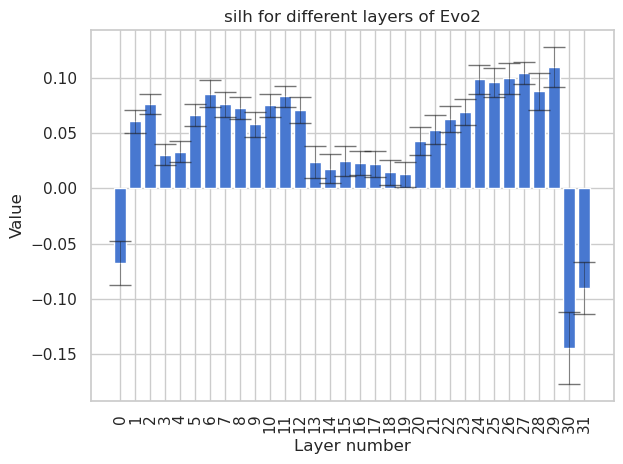

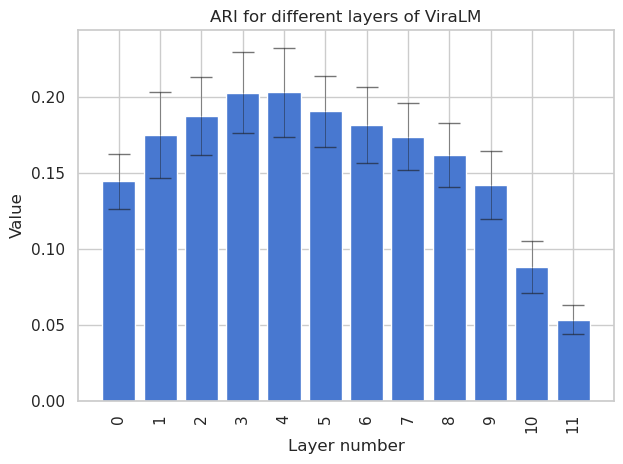

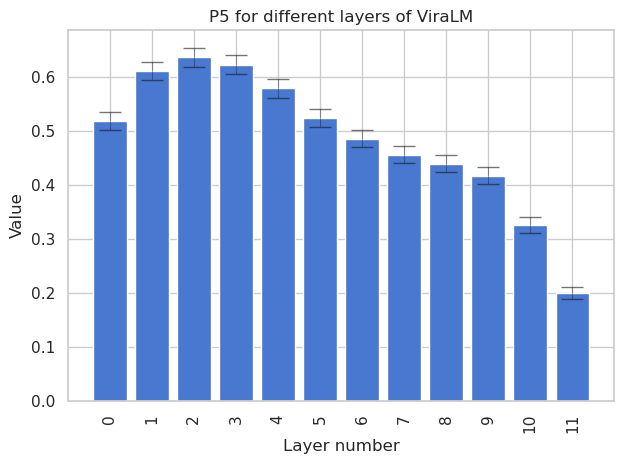

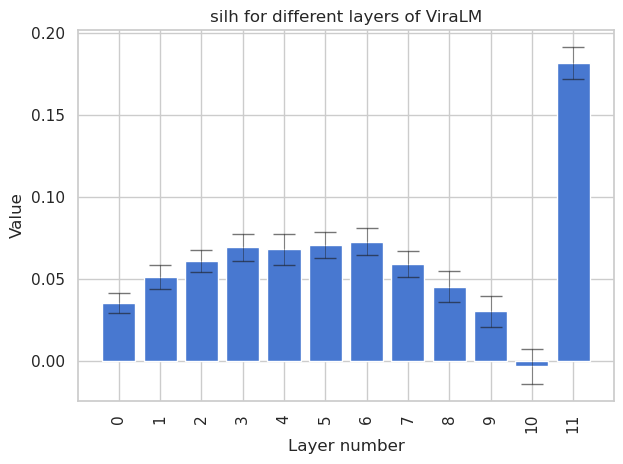

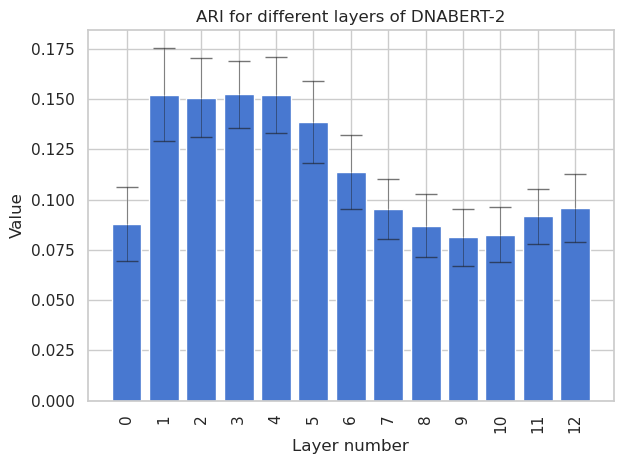

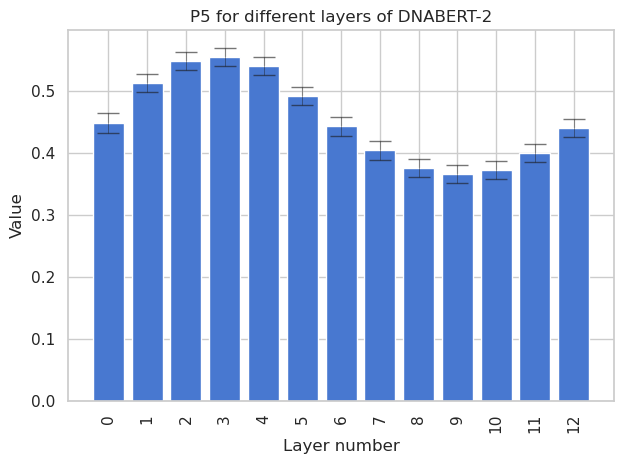

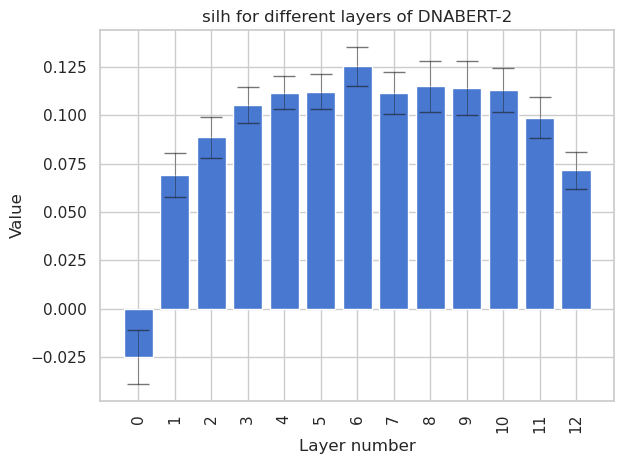

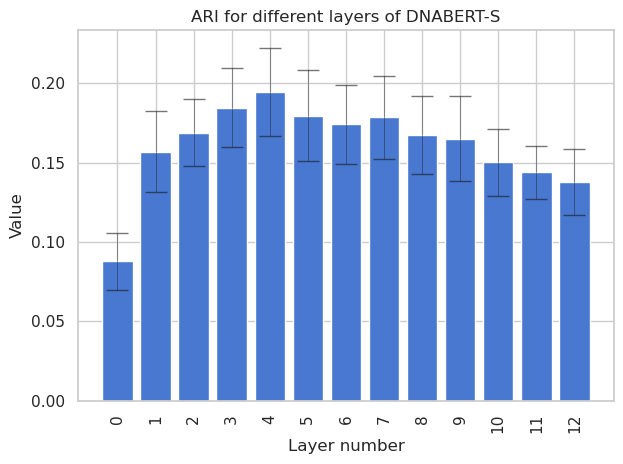

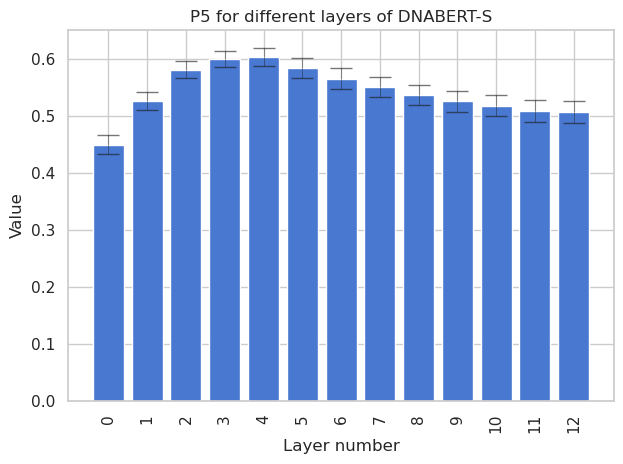

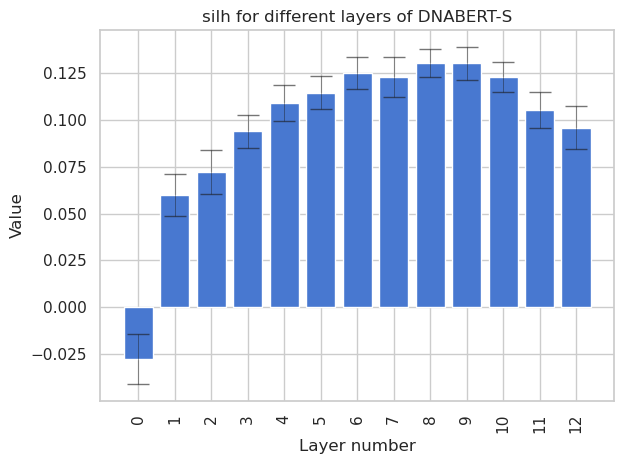

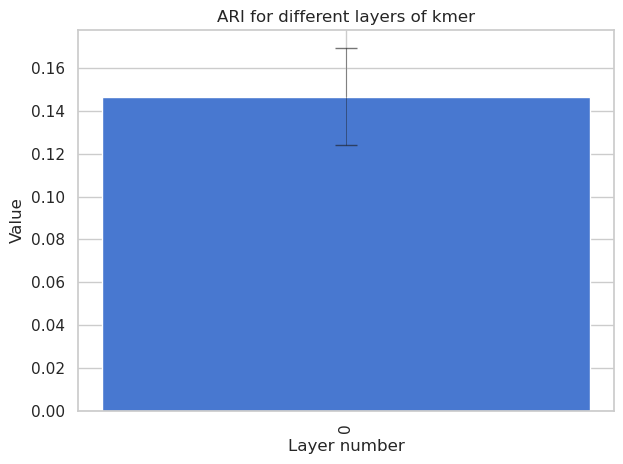

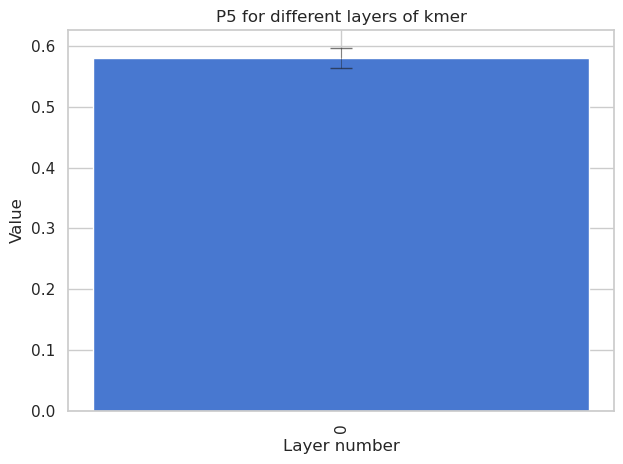

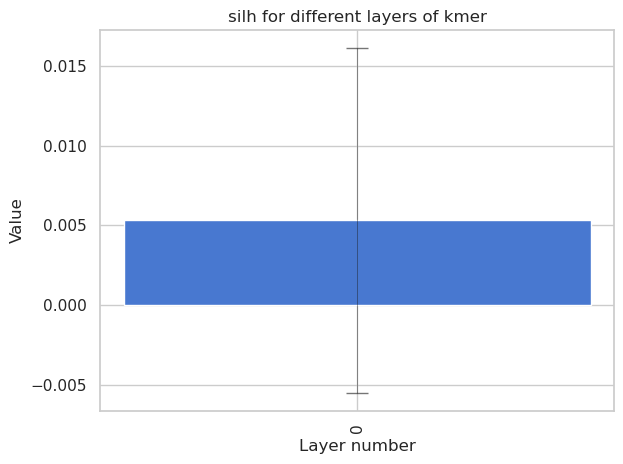

In [111]:
metrics = ['ARI', 'P5', 'silh']
models = ['evo2', 'viralm','dnabert2', 'dnabertS', 'kmer']
models_ = ['Evo2', 'ViraLM', 'DNABERT-2', 'DNABERT-S', 'kmer']
best = {metric: {m: [] for m in models_} for metric in metrics}
for mdl in models:
    for metr in metrics:
        df = pd.read_excel(f'../data/metrics/{mdl}/{metr}.xlsx')
        if mdl == 'evo2':
            mdl_ = 'Evo2'
        elif mdl == 'viralm':
            mdl_ = 'ViraLM'
        elif mdl == 'dnabert2':
            mdl_ = 'DNABERT-2'
        elif mdl == 'dnabertS':
            mdl_ = 'DNABERT-S'
        elif mdl == 'kmer':
            mdl_ = 'kmer'
        elif mdl == 'genalm':
            mdl_ = 'GenaLM'
        if metr == 'P5':
            metr_ = 'Precision@5'
        if metr == 'silh':
            metr_ = 'Silhouette'
        visualize_metrics(df, model_name = mdl_, metric_name = metr, save = True)
        best[metr][mdl_] = (df.mean(axis = 1).argmax(), df.mean(axis = 1).max(), df.iloc[df.mean(axis = 1).argmax(), :].std())

In [112]:
best

{'ARI': {'Evo2': (26, 0.2647423858831617, 0.030689003032618626),
  'ViraLM': (4, 0.20302222100103262, 0.02918951243678916),
  'DNABERT-2': (3, 0.15238883271089224, 0.016751634237532342),
  'DNABERT-S': (4, 0.19474214403717408, 0.027633740429510743),
  'kmer': (0, 0.1467944770623447, 0.022537538050984282)},
 'P5': {'Evo2': (26, 0.6126451934915715, 0.017403519738970554),
  'ViraLM': (2, 0.6373919015233995, 0.017328551326739897),
  'DNABERT-2': (3, 0.5551969580027709, 0.014769499142643186),
  'DNABERT-S': (4, 0.6032615307905397, 0.0159047475400929),
  'kmer': (0, 0.5806840200282636, 0.0159431532558459)},
 'silh': {'Evo2': (29, 0.11000201016664506, 0.018254767561310753),
  'ViraLM': (11, 0.18196040868759156, 0.0096005016444562),
  'DNABERT-2': (6, 0.1252418865263462, 0.00990269032341337),
  'DNABERT-S': (8, 0.13035725936293602, 0.007526986322749725),
  'kmer': (0, 0.005307037980898216, 0.010837921016533409)}}

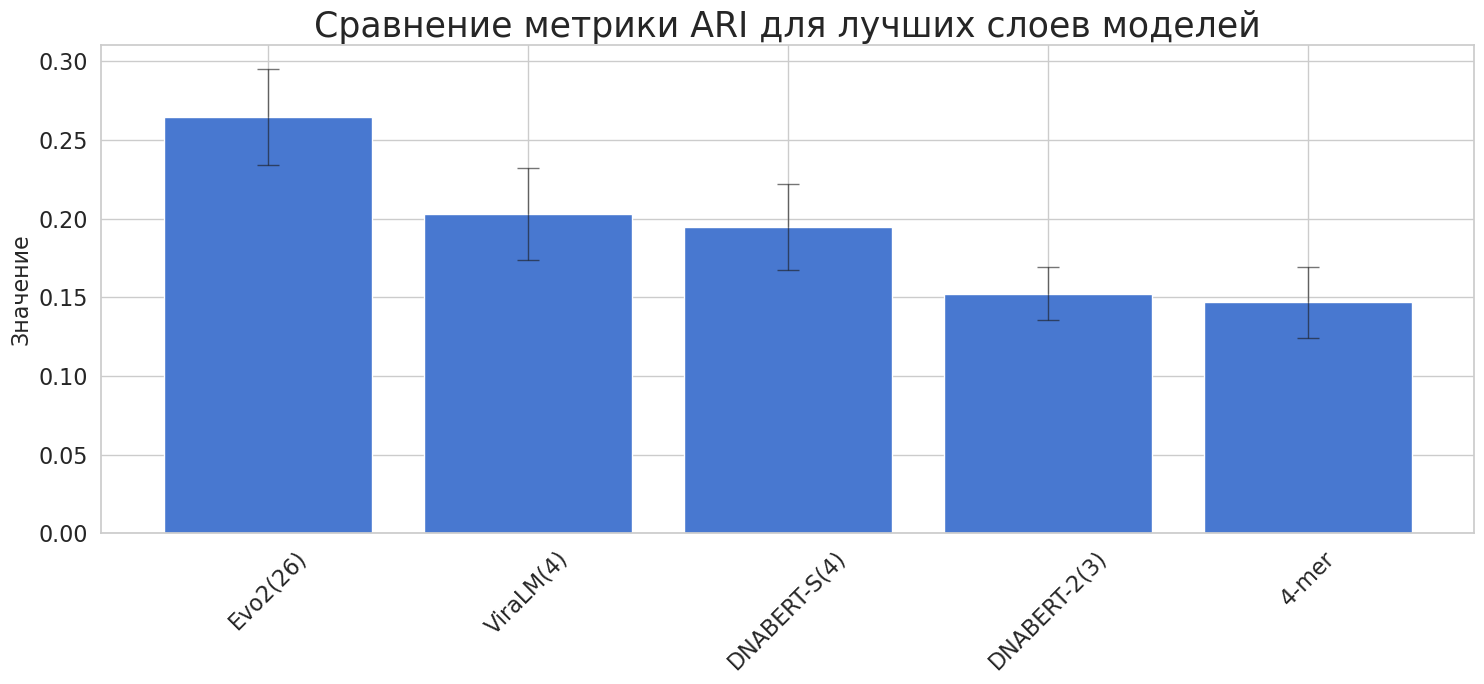

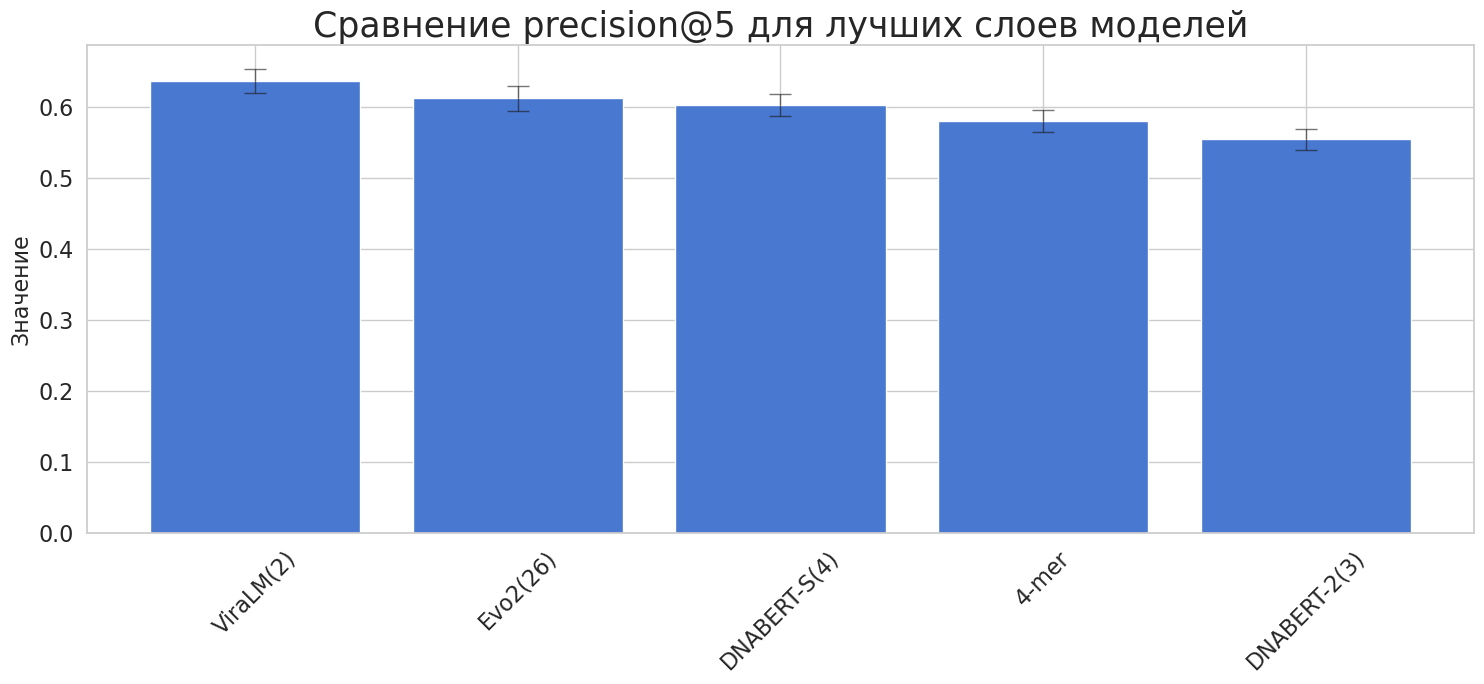

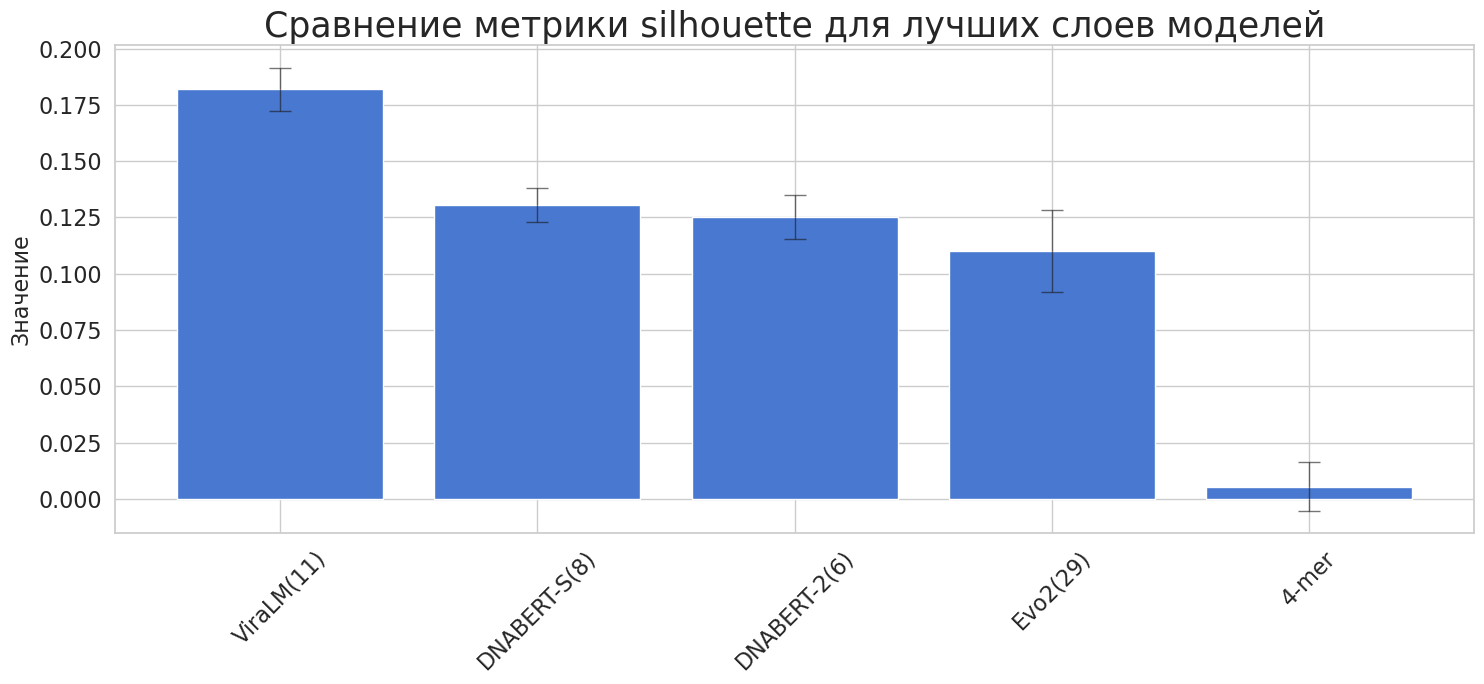

In [80]:
for k in best:    
    
    layers = [(str(x) + '(' + str(best[k][x][0])) + ')' if x != 'kmer' else '4-mer' for x in best[k]]
    means = [best[k][x][1] for x in best[k]]
    stds = [best[k][x][2] for x in best[k]]

    sorted_data = sorted(zip(means, stds, layers), reverse=True)
    means, stds, layers = zip(*sorted_data)

    plt.figure(figsize=(15, 7))
    plt.bar(
        layers,
        means,
        yerr=stds,
        capsize=8,
        error_kw={
            "elinewidth": 1,
            "capthick": 1,
            "alpha": 0.6
        }
    )
    if k == 'P5':
        plt.title(f"Сравнение precision@5 для лучших слоев моделей", fontsize=25)
    elif k == 'silh':
        plt.title(f"Сравнение метрики silhouette для лучших слоев моделей", fontsize=25)
    else:
        plt.title(f"Сравнение метрики ARI для лучших слоев моделей", fontsize=25)

    
    # if k == 'P5':
    #     plt.title(f"Comparison of precision@5 metrics on the best model layers", fontsize=25)
    # elif k == 'silh':
    #     plt.title(f"Comparison of silhouette metrics on the best model layers", fontsize=25)
    # else:
    #     plt.title(f"Comparison of {k} metrics on the best model layers", fontsize=25)
    

    plt.ylabel("Значение", fontsize=16)
    plt.xticks(rotation=45, fontsize=16)
    plt.yticks(fontsize=16)
    plt.tight_layout()
    plt.savefig(f"../data/metrics/compare_metrics/COMPARE_{k}.png", dpi=300, bbox_inches='tight')
    plt.show()

In [113]:
def visualize_metrics(df, model_name, metric_name, virus, save = False):
    df_sorted = df.sort_index()
    means = df_sorted.mean(axis=1)
    stds = df_sorted.std(axis=1)
    
    layers = df_sorted.index
    
    # Один barplot с "усами"
    plt.figure()
    plt.bar(
        layers,
        means,
        yerr=stds,
        capsize=8,                 
        error_kw={
            "elinewidth": 0.5,     
            "capthick": 1,         
            "alpha": 0.6
        }
    )


    
    plt.title(f"Precision@5 for different layers of {model_name} ({virus})")
    plt.xlabel("Layer number")
    plt.ylabel("Value")

    plt.xticks(layers, rotation=90)
    plt.tight_layout()
    if save:
        plt.savefig(f'../data/metrics/compare_metrics/{model_name}_{metric_name}_{virus}.png')
    plt.show()

../data/metrics/evo2/P@5_matrix_Mriyavirales_preproc.xlsx


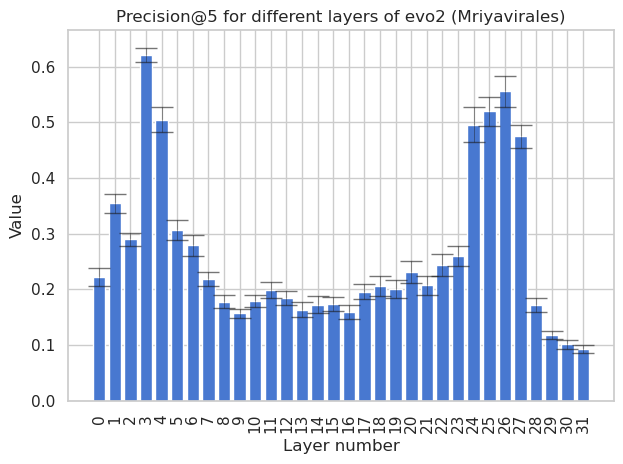

../data/metrics/viralm/P@5_matrix_Mriyavirales_preproc.xlsx


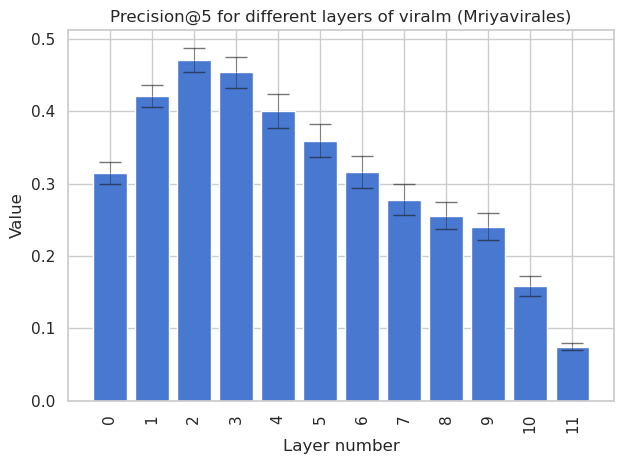

../data/metrics/dnabert2/P@5_matrix_Mriyavirales_preproc.xlsx


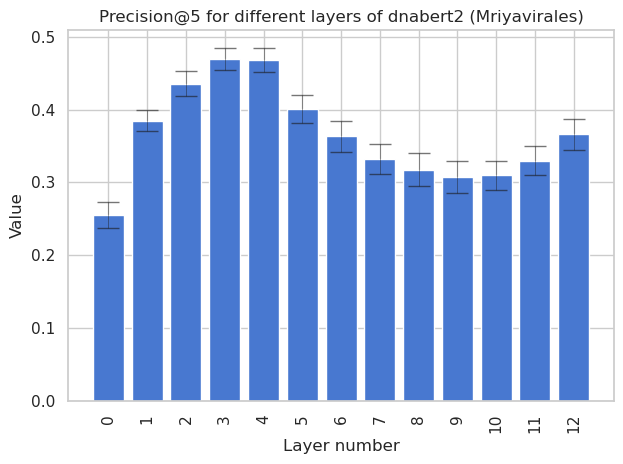

../data/metrics/dnabertS/P@5_matrix_Mriyavirales_preproc.xlsx


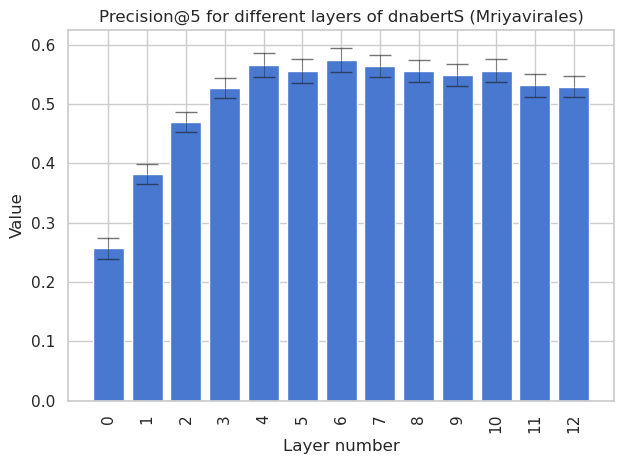

../data/metrics/kmer/P@5_matrix_Mriyavirales_preproc.xlsx


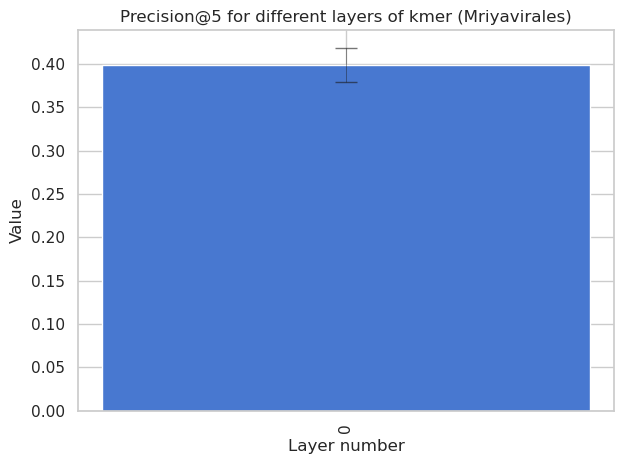

../data/metrics/evo2/P@5_matrix_Egovirales_preproc.xlsx


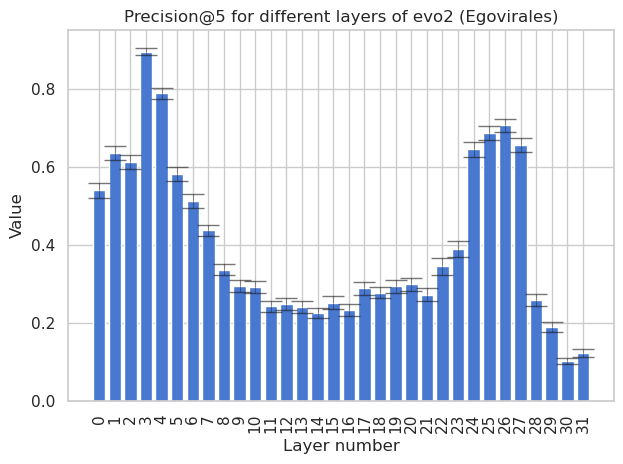

../data/metrics/viralm/P@5_matrix_Egovirales_preproc.xlsx


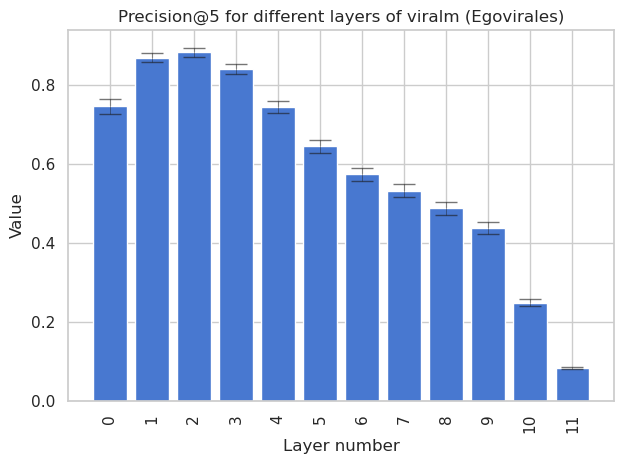

../data/metrics/dnabert2/P@5_matrix_Egovirales_preproc.xlsx


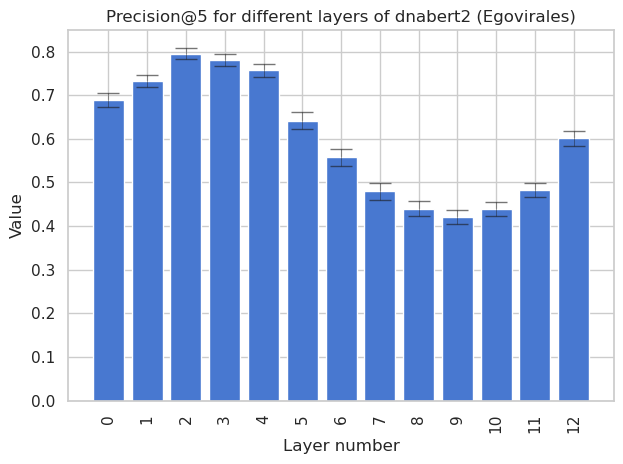

../data/metrics/dnabertS/P@5_matrix_Egovirales_preproc.xlsx


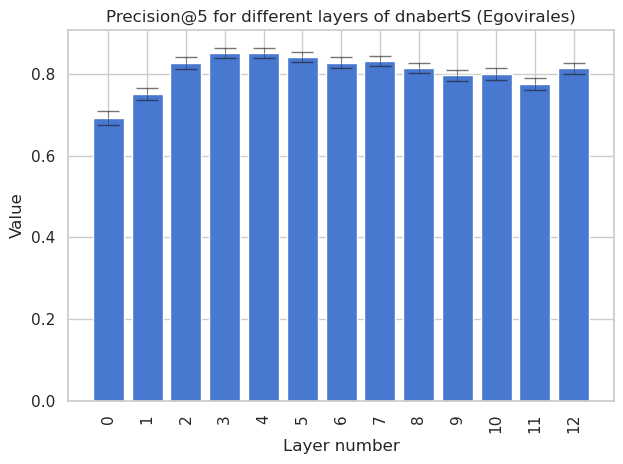

../data/metrics/kmer/P@5_matrix_Egovirales_preproc.xlsx


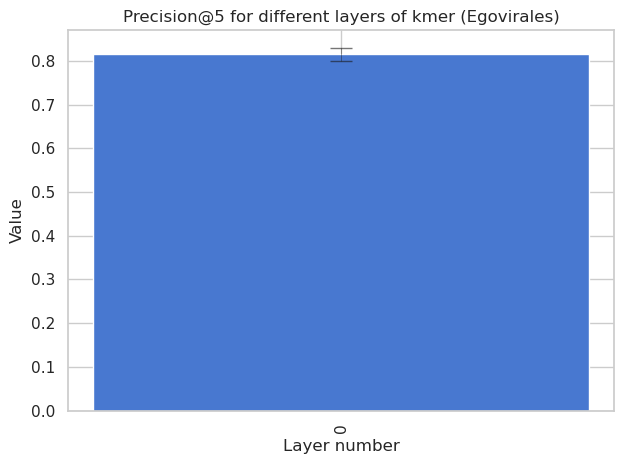

../data/metrics/evo2/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


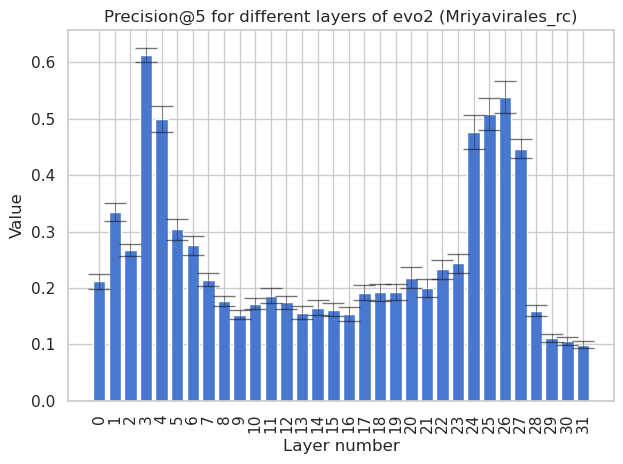

../data/metrics/viralm/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


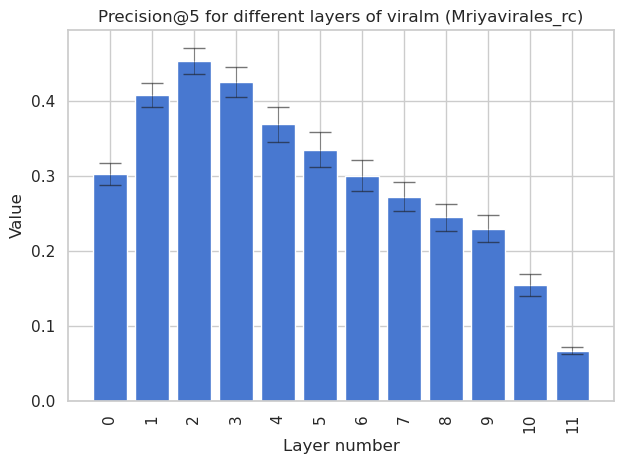

../data/metrics/dnabert2/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


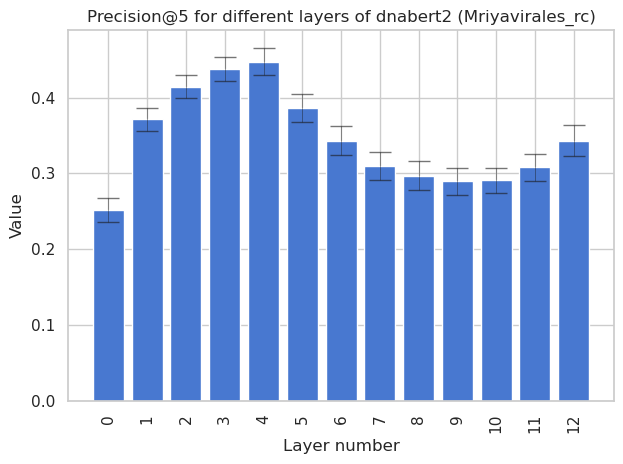

../data/metrics/dnabertS/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


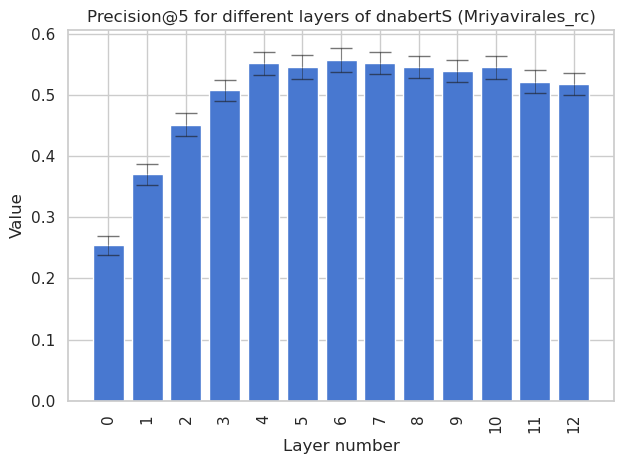

../data/metrics/kmer/P@5_matrix_REVERSECOMPLEMENTMriyavirales_preproc.xlsx


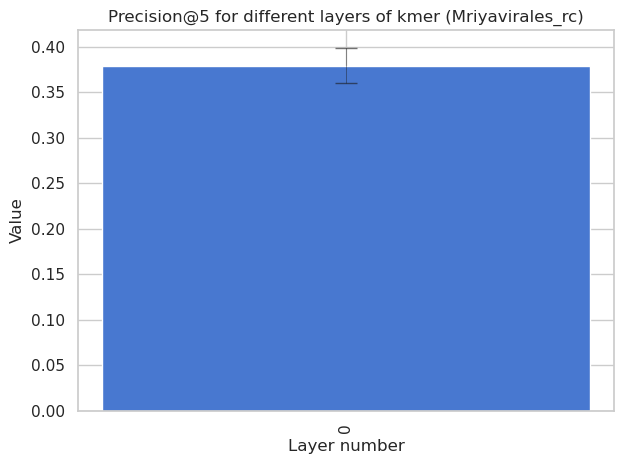

../data/metrics/evo2/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


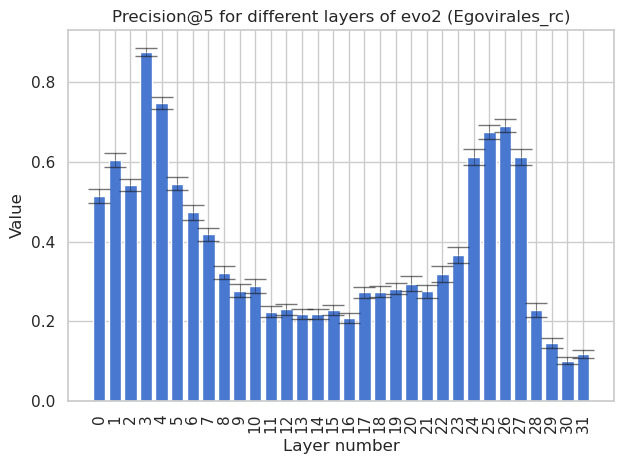

../data/metrics/viralm/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


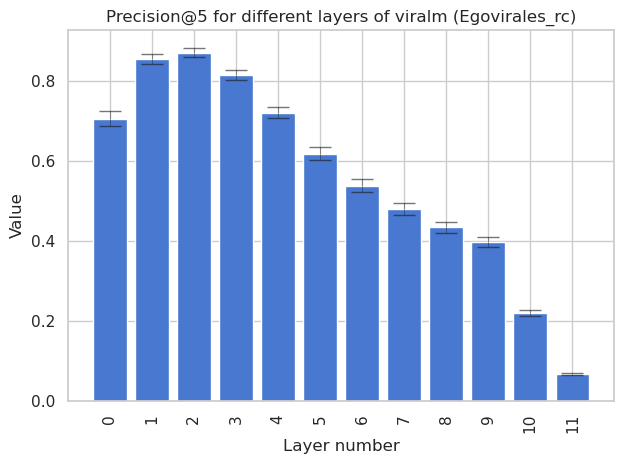

../data/metrics/dnabert2/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


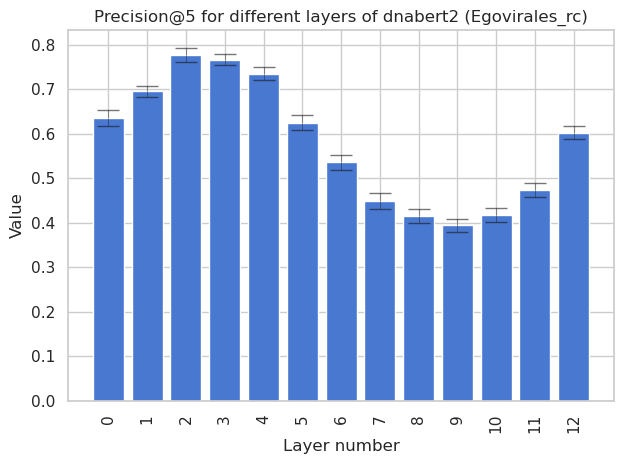

../data/metrics/dnabertS/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


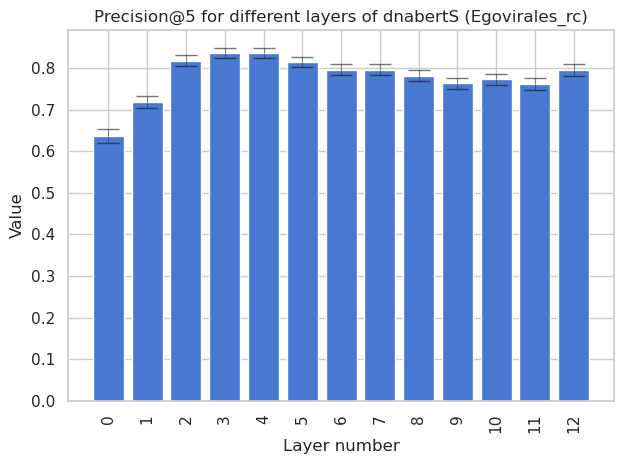

../data/metrics/kmer/P@5_matrix_REVERSECOMPLEMENTEgovirales_preproc.xlsx


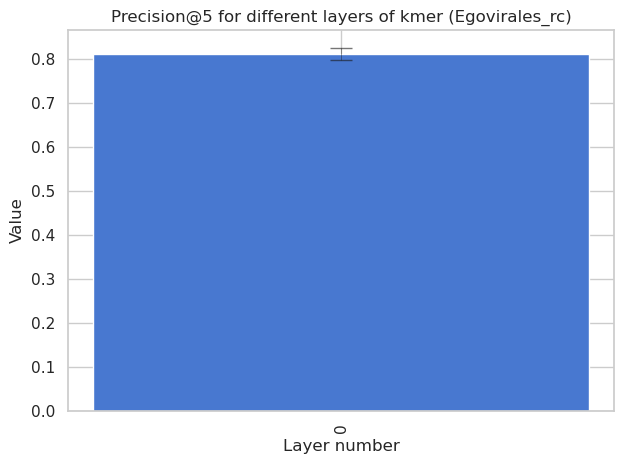

In [114]:
metrics = ['P@5']
UNK_viruses = ['Mriyavirales_preproc', 'Egovirales_preproc', 'REVERSECOMPLEMENTMriyavirales_preproc', 'REVERSECOMPLEMENTEgovirales_preproc']
models = ['evo2', 'viralm','dnabert2', 'dnabertS', 'kmer']

best = {vir: {metric: {m: [] for m in models} for metric in metrics} for vir in UNK_viruses}

for vir in UNK_viruses:
    for mdl in models:
        for metr in metrics:
            path = f'../data/metrics/{mdl}/{metr}_matrix_{vir}.xlsx'
            df = pd.read_excel(path)
            print(path)
            df = df.iloc[:, 1:]
            if vir.startswith('REVERSECOMPLEMENT'):
                name = f'{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}' + '_rc'
            else:
                name = f'{vir.split('_')[0]}'
                
            visualize_metrics(df.iloc[:, 1:], model_name = mdl, virus = name, metric_name = metr, save = True)
            if metr == 'P@K' or metr == 'P@1' or metr == 'P@5':
                best[vir][metr][mdl] = (df.mean(axis = 1).argmax(), df.mean(axis = 1).max(), df.iloc[df.mean(axis = 1).argmax(), :].std())
            else:
                best[vir][metr][mdl] = (df.mean(axis = 1).argmin(), df.mean(axis = 1).min(), df.iloc[df.mean(axis = 1).argmin(), :].std())

In [117]:
best

{'Mriyavirales_preproc': {'P@5': {'evo2': (3,
    0.6212666666666666,
    0.012370875019691821),
   'viralm': (2, 0.4700917056530215, 0.016993601985864106),
   'dnabert2': (3, 0.4693066666666666, 0.014492759940844513),
   'dnabertS': (6, 0.5741866666666667, 0.020375962896157274),
   'kmer': (0, 0.39812000000000003, 0.01943822822567138)}},
 'Egovirales_preproc': {'P@5': {'evo2': (3,
    0.896406557377049,
    0.009437668303481717),
   'viralm': (2, 0.8808263851528535, 0.011401991364110308),
   'dnabert2': (2, 0.7958098360655739, 0.013355648097797147),
   'dnabertS': (4, 0.8510229508196724, 0.012226509345772702),
   'kmer': (0, 0.8145311475409837, 0.013870091778593732)}},
 'REVERSECOMPLEMENTMriyavirales_preproc': {'P@5': {'evo2': (3,
    0.61328,
    0.012048910151032923),
   'viralm': (2, 0.4531615448343081, 0.017447581708671722),
   'dnabert2': (4, 0.4480133333333333, 0.018380207238782427),
   'dnabertS': (6, 0.55694, 0.01998601438444034),
   'kmer': (0, 0.37903333333333333, 0.01900593

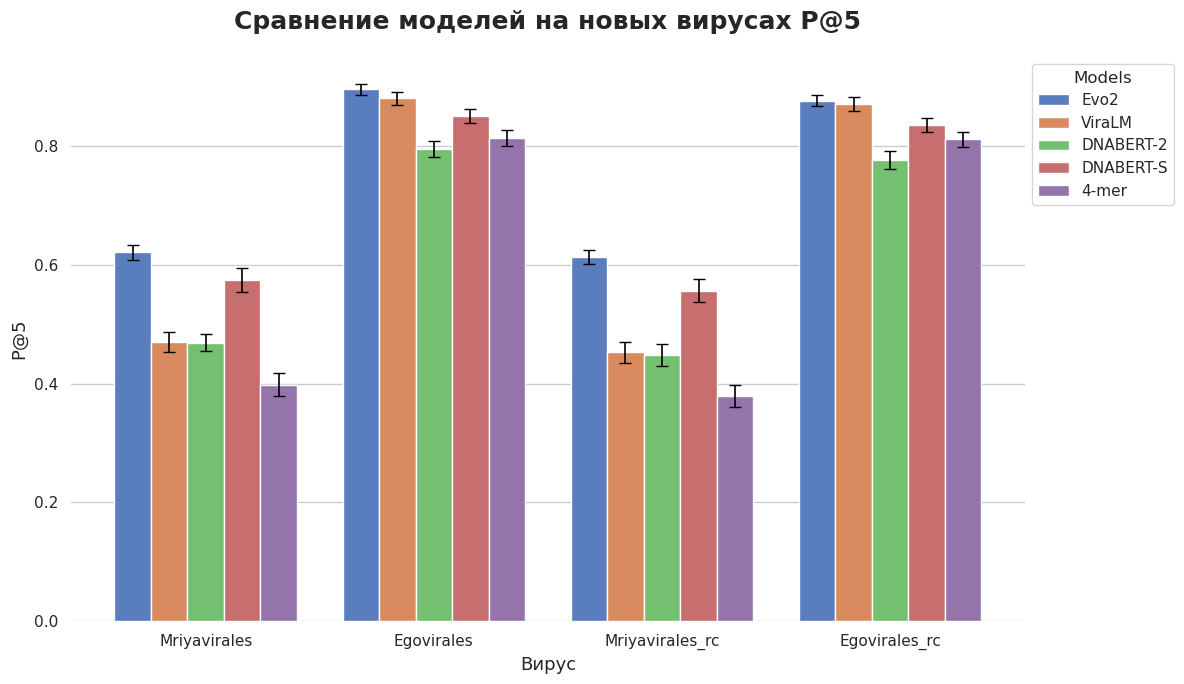

In [118]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Словарь для переименования моделей
model_mapping = {
    "kmer": "4-mer",
    "evo2": "Evo2",
    "dnabert2": "DNABERT-2",
    "dnabertS": "DNABERT-S",
    "viralm": "ViraLM",
}

data_list = []
for vir, metrics_dict in best.items():
    clean_name = (
        f"{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}_rc"
        if "REVERSECOMPLEMENT" in vir
        else vir.split("_")[0]
    )
    for metr, models_dict in metrics_dict.items():
        for mdl, results in models_dict.items():
            # Применяем переименование (если имени нет в словаре, оставляем прежнее)
            display_name = model_mapping.get(mdl, mdl)

            data_list.append(
                {
                    "Virus": clean_name,
                    "Model": display_name,  # Используем красивое имя
                    "Metric": metr,
                    "Score": results[1],
                    "Std": results[2],
                }
            )

df_plot = pd.DataFrame(data_list)

sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(12, 7))

# 2. Обновляем порядок моделей, чтобы он совпадал с новыми названиями
model_order = [model_mapping.get(m, m) for m in models]

sns.barplot(
    data=df_plot,
    x="Virus",
    y="Score",
    hue="Model",
    hue_order=model_order,
    ax=ax,
)


for i, model_name in enumerate(model_order):
    model_data = (
        df_plot[df_plot["Model"] == model_name]
        .set_index("Virus")
        .reindex(df_plot["Virus"].unique())
    )

    x_coords = [
        patch.get_x() + patch.get_width() / 2 for patch in ax.containers[i]
    ]
    y_coords = model_data["Score"].values
    y_err = model_data["Std"].values

    ax.errorbar(
        x_coords,
        y_coords,
        yerr=y_err,
        fmt="none",
        c="black",
        capsize=4,
        elinewidth=1.2,
        zorder=3,
    )

ax.set_title(
    f"Сравнение моделей на новых вирусах {metrics[0]}",
    fontsize=18,
    fontweight="bold",
    pad=20,
)
ax.set_ylabel("P@5", fontsize=13)
ax.set_xlabel("Вирус", fontsize=13)

ax.legend(
    title="Models", bbox_to_anchor=(1, 1), loc="upper left", frameon=True
)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(f"../data/metrics/compare_metrics/Model_comparison_new_vir.png")
plt.show()


In [119]:
x_coords


[0.31999999999999995, 1.3199999999999998, 2.32, 3.32]

In [120]:
best

{'Mriyavirales_preproc': {'P@5': {'evo2': (3,
    0.6212666666666666,
    0.012370875019691821),
   'viralm': (2, 0.4700917056530215, 0.016993601985864106),
   'dnabert2': (3, 0.4693066666666666, 0.014492759940844513),
   'dnabertS': (6, 0.5741866666666667, 0.020375962896157274),
   'kmer': (0, 0.39812000000000003, 0.01943822822567138)}},
 'Egovirales_preproc': {'P@5': {'evo2': (3,
    0.896406557377049,
    0.009437668303481717),
   'viralm': (2, 0.8808263851528535, 0.011401991364110308),
   'dnabert2': (2, 0.7958098360655739, 0.013355648097797147),
   'dnabertS': (4, 0.8510229508196724, 0.012226509345772702),
   'kmer': (0, 0.8145311475409837, 0.013870091778593732)}},
 'REVERSECOMPLEMENTMriyavirales_preproc': {'P@5': {'evo2': (3,
    0.61328,
    0.012048910151032923),
   'viralm': (2, 0.4531615448343081, 0.017447581708671722),
   'dnabert2': (4, 0.4480133333333333, 0.018380207238782427),
   'dnabertS': (6, 0.55694, 0.01998601438444034),
   'kmer': (0, 0.37903333333333333, 0.01900593

In [121]:
UNK_viruses

['Mriyavirales_preproc',
 'Egovirales_preproc',
 'REVERSECOMPLEMENTMriyavirales_preproc',
 'REVERSECOMPLEMENTEgovirales_preproc']

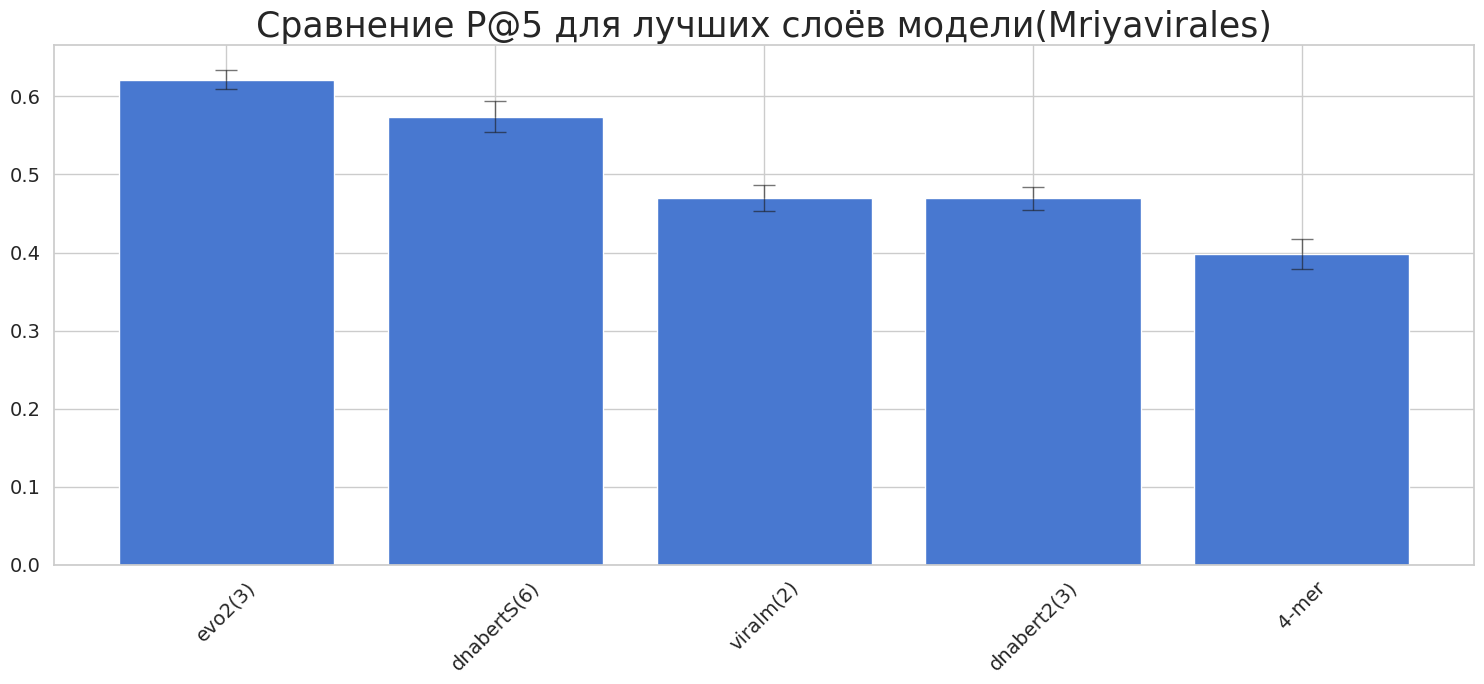

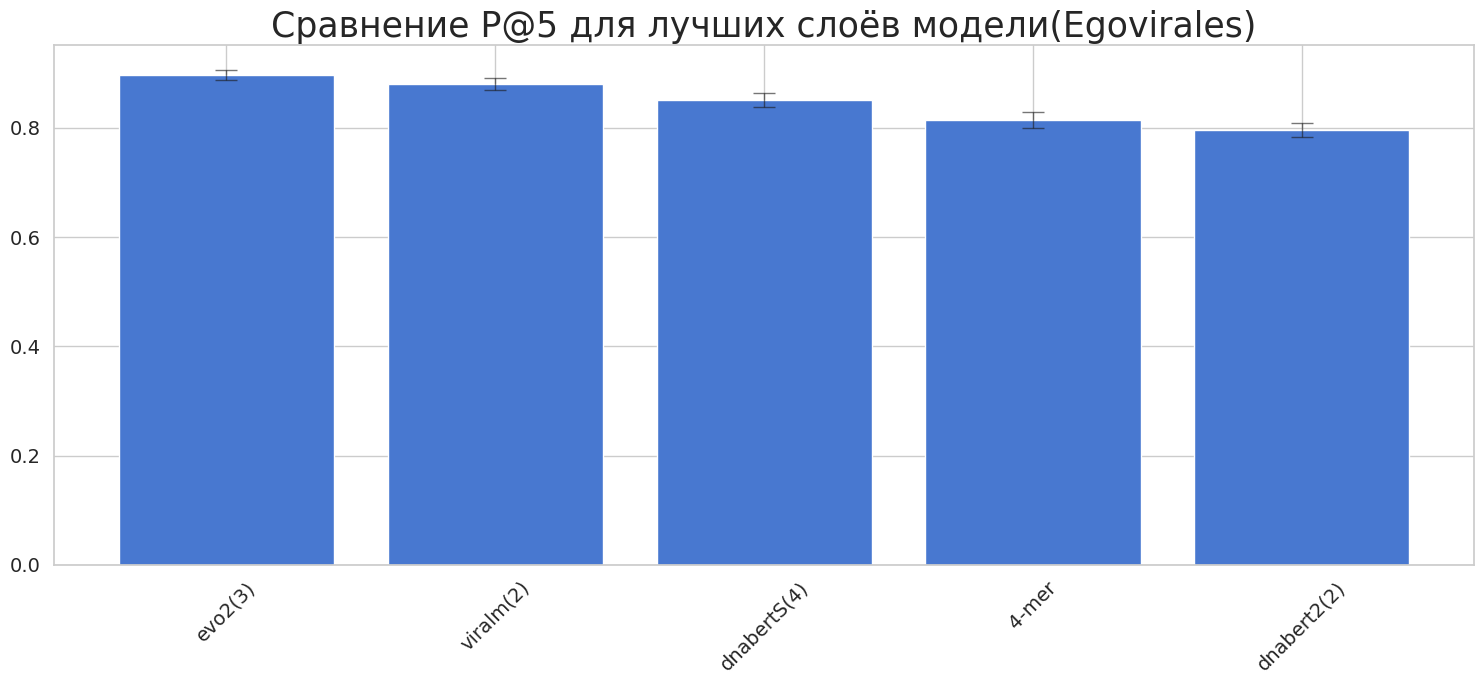

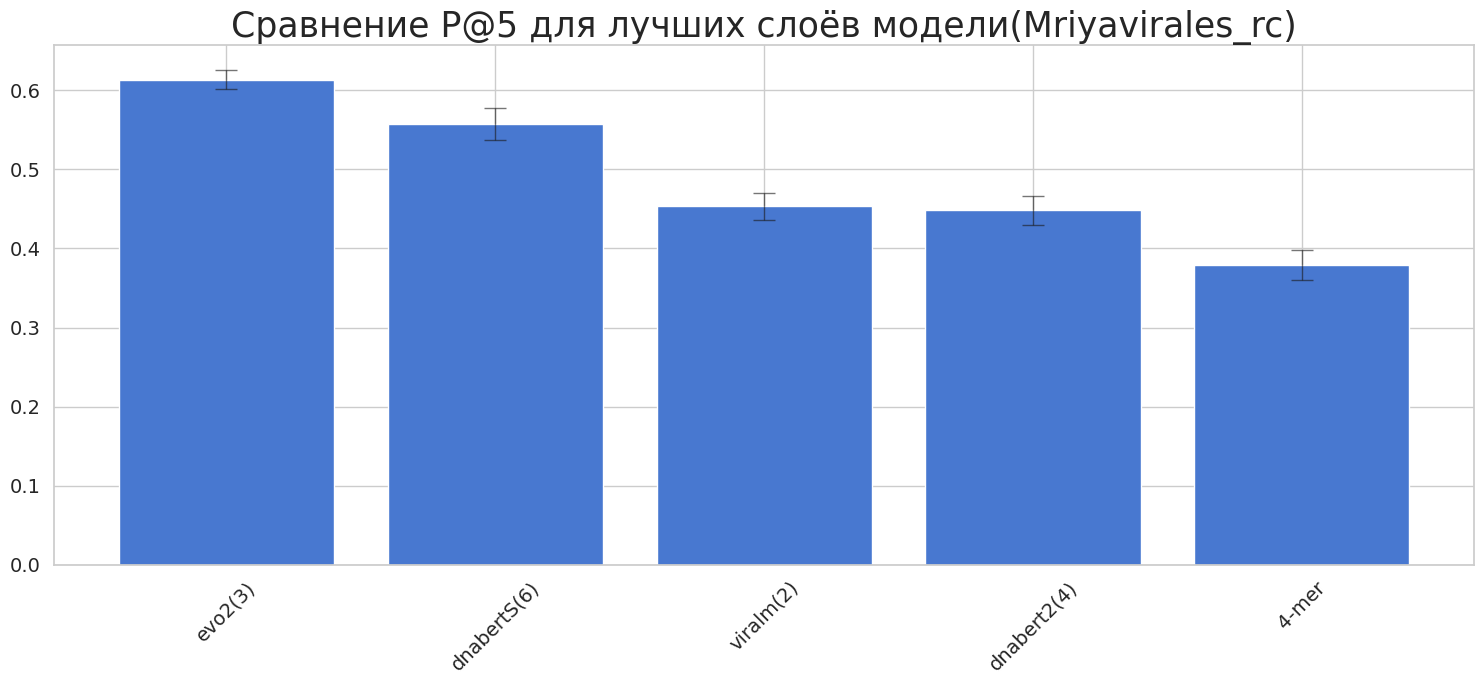

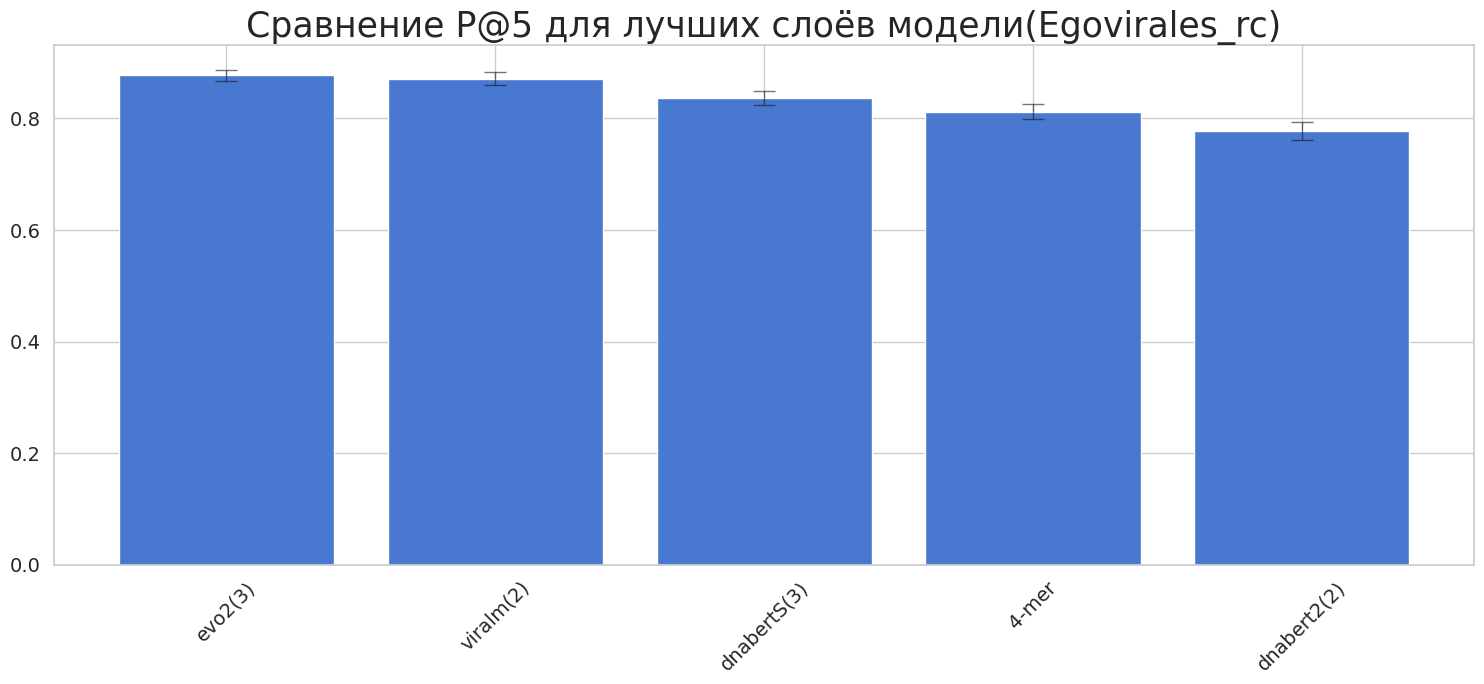

In [122]:
for vir in UNK_viruses:
    for k in best[vir]:
        
        layers = [(str(x) + '(' + str(best[vir][k][x][0])) + ')' if x != 'kmer' else '4-mer' for x in best[vir][k]]
        means = [best[vir][k][x][1] for x in best[vir][k]]
        stds = [best[vir][k][x][2] for x in best[vir][k]]

        sorted_data = sorted(zip(means, stds, layers), reverse=True)
        means, stds, layers = zip(*sorted_data)

        plt.figure(figsize=(15, 7))
        plt.bar(
            layers,
            means,
            yerr=stds,
            capsize=8,
            error_kw={
                "elinewidth": 1,
                "capthick": 1,
                "alpha": 0.6
            }
        )

        if vir.startswith('REVERSECOMPLEMENT'):
            name = f'{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}' + '_rc'
        else:
            name = f'{vir.split('_')[0]}'
        plt.title(f"Сравнение {k} для лучших слоёв модели({name})", fontsize = 25)
        plt.xticks(rotation=45, fontsize=14)
        plt.yticks(fontsize=14)
        plt.tight_layout()
        plt.savefig(f"../data/metrics/compare_metrics/COMPARE_{k}_{name}.png")
        plt.show()

In [123]:
df = pd.concat([pd.read_excel('../data/metrics/P@K_new_virus/P@5.xlsx'), pd.read_excel('../data/metrics/P@5_genalm.xlsx')])
best = {}

for _, row in df[df['type'] == 'cross'].iterrows():
    vir = row['virus']
    metr = row['type']
    mdl = row['model']
    
    if vir not in best:
        best[vir] = {}
    if metr not in best[vir]:
        best[vir][metr] = {}
    
    
    best[vir][metr][mdl] = (
        row['best_layer'], 
        row['mean_P@K'], 
        row['std_P@K']
    )

In [124]:
best

{'Mriyavirales_preproc': {'cross': {'kmer': ('-', 0.3405, 0.0193),
   'dnabert2': (4, 0.4831, 0.0177),
   'viralm': (3, 0.4627, 0.0156),
   'dnabertS': (7, 0.6522, 0.0155),
   'evo2': (3, 0.698, 0.011),
   'genalm_base': (1, 0.3242, 0.0166),
   'genalm': (1, 0.3242, 0.0166)}},
 'Egovirales_preproc': {'cross': {'kmer': ('-', 0.6107, 0.0224),
   'dnabertS': (12, 0.8487, 0.0121),
   'dnabert2': (2, 0.6547, 0.021),
   'viralm': (3, 0.7814, 0.0156),
   'evo2': (3, 0.8814, 0.0095),
   'genalm_base': (11, 0.5993, 0.0212),
   'genalm': (11, 0.5993, 0.0212)}}}

In [105]:
models

['evo2', 'viralm', 'dnabert2', 'dnabertS', 'kmer']

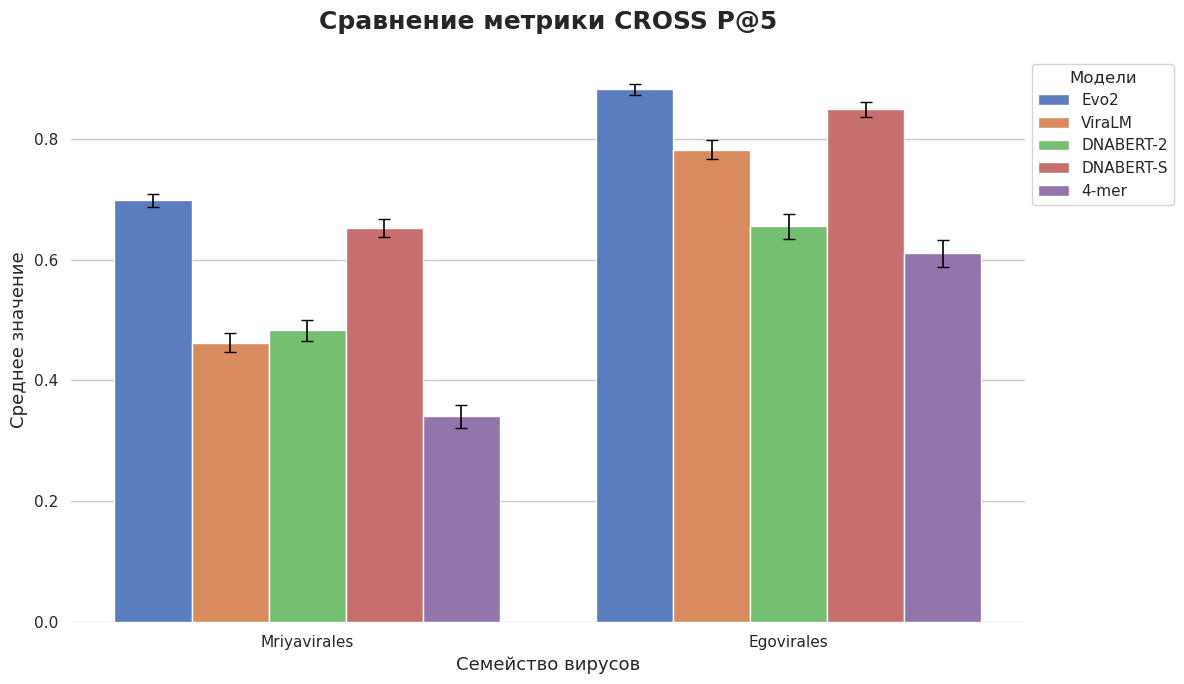

In [107]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Словарь для переименования моделей
model_mapping = {
    "kmer": "4-mer",
    "evo2": "Evo2",
    "dnabert2": "DNABERT-2",
    "dnabertS": "DNABERT-S",
    "viralm": "ViraLM",
}

data_list = []
for vir, metrics_dict in best.items():
    clean_name = (
        f"{vir.split('REVERSECOMPLEMENT')[-1].split('_')[0]}_rc"
        if "REVERSECOMPLEMENT" in vir
        else vir.split("_")[0]
    )
    for metr, models_dict in metrics_dict.items():
        for mdl, results in models_dict.items():
            # Заменяем старое название модели на красивое
            display_name = model_mapping.get(mdl, mdl)

            data_list.append(
                {
                    "Virus": clean_name,
                    "Model": display_name,  # Используем новое название
                    "Metric": metr,
                    "Score": results[1],
                    "Std": results[2],
                }
            )

df_plot = pd.DataFrame(data_list)

sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(12, 7))

# Переименовываем элементы в порядке моделей для корректного отображения hue_order
model_order = [model_mapping.get(m, m) for m in models]

sns.barplot(
    data=df_plot,
    x="Virus",
    y="Score",
    hue="Model",
    hue_order=model_order,
    ax=ax,
)

for i, model_name in enumerate(model_order):
    model_data = (
        df_plot[df_plot["Model"] == model_name]
        .set_index("Virus")
        .reindex(df_plot["Virus"].unique())
    )

    x_coords = [
        patch.get_x() + patch.get_width() / 2 for patch in ax.containers[i]
    ]
    y_coords = model_data["Score"].values
    y_err = model_data["Std"].values

    ax.errorbar(
        x_coords,
        y_coords,
        yerr=y_err,
        fmt="none",
        c="black",
        capsize=4,
        elinewidth=1.2,
        zorder=3,
    )

ax.set_title(
    f"Сравнение метрики CROSS P@5",
    fontsize=18,
    fontweight="bold",
    pad=20,
)
ax.set_ylabel("Среднее значение", fontsize=13)
ax.set_xlabel("Семейство вирусов", fontsize=13)

ax.legend(
    title="Модели", bbox_to_anchor=(1, 1), loc="upper left", frameon=True
)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(
    f"../data/metrics/compare_metrics/Model_comparison_CROSS_new_vir.png"
)
plt.show()
